<a href="https://colab.research.google.com/github/matheusgustavo23/ciencia-de-dados-unijui/blob/main/eleicao_governador_RS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Como o RS votou para governador em 2026

Programação para Ciência de Dados
MATHEUS GUSTAVO BARBOSA FREDDI

**Fonte dos dados:** Portal de Dados Abertos do TSE (https://dadosabertos.tse.jus.br/), conjunto Resultados 2026, arquivo "Votação por seção eleitoral" do RS (votacao_secao_2026_RS.zip).

## 1. Definição do problema

Tema: eleição para governador do Rio Grande do Sul, 1º turno de 2026

Pergunta principal: como os votos para governador se distribuíram pelo estado?

O que eu quero descobrir:
1. Quantos votos e qual percentual cada candidato teve? A eleição acabou no 1º turno?
2. Quantas pessoas votaram em branco ou nulo?
3. Quem ganhou em cada município e quantos municípios cada candidato ganhou?
4. O voto foi diferente nas cidades grandes e nas cidades pequenas?

## 2. Obtendo e explorando os dados
### 2.1 Bibliotecas

In [1]:
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

### 2.2 Abrindo o arquivo
No Colab, arraste o arquivo votacao_secao_2026_RS.zip para a pasta da esquerda (demora um pouco, são 140 MB).
O zip tem o CSV com os votos e um PDF (leiame.pdf) que explica as colunas. Primeiro eu descompacto.

In [2]:
with zipfile.ZipFile("votacao_secao_2026_RS.zip") as z:
    print(z.namelist())
    z.extractall()

['votacao_secao_2026_RS.csv', 'leiame.pdf']


O CSV tem mais de 1 GB. Antes de abrir tudo, leio só as primeiras 1000 linhas para ver como ele é.
Os arquivos do TSE usam ; como separador e codificação latin1 (por causa dos acentos).

In [3]:
amostra = pd.read_csv("votacao_secao_2026_RS.csv", sep=";", encoding="latin1", nrows=1000)

print("Número de colunas:", len(amostra.columns))
amostra.head()

Número de colunas: 26


,DT_GERACAO,HH_GERACAO,ANO_ELEICAO,CD_TIPO_ELEICAO,NM_TIPO_ELEICAO,NR_TURNO,CD_ELEICAO,DS_ELEICAO,DT_ELEICAO,TP_ABRANGENCIA,...,NR_SECAO,CD_CARGO,DS_CARGO,NR_VOTAVEL,NM_VOTAVEL,QT_VOTOS,NR_LOCAL_VOTACAO,SQ_CANDIDATO,NM_LOCAL_VOTACAO,DS_LOCAL_VOTACAO_ENDERECO
0,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,159,7,Deputado Estadual,20700,DEISI SILVEIRA REINALDO,2,1899,210002534305,EEEM OSVALDO ARANHA,"RUA TIMBAÚVA, 931"
1,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,295,7,Deputado Estadual,12312,GERSON BURMANN,1,1848,210002539809,SALÃO COMUNITÁRIO DA MONTANHA,"AVENIDA BENJAMIN CONSTANT, 3774."
2,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,295,7,Deputado Estadual,15715,RODRIGO ALENCAR BOHN GLINKE,2,1848,210002548226,SALÃO COMUNITÁRIO DA MONTANHA,"AVENIDA BENJAMIN CONSTANT, 3774."
3,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,24,7,Deputado Estadual,10107,MARLI RIBEIRO SERPA,5,1317,210002539103,COLEGIO EST. ENGENHEIRO IGNACIO CHRISTIANO PLA...,"RUA GUILHERME OSCAR ODY, 153"
4,06/10/2026,14:03:43,2026,2,Eleição Ordinária,1,6259,Eleições Gerais Estaduais 2026,04/10/2026,E,...,39,7,Deputado Estadual,11234,VOLMIR RODRIGUES,2,1252,210002537880,EMEB PRESIDENTE NILO PEÇANHA,"RUA TUPINIQUINS, 134"


In [4]:
# tipos de dados de cada coluna
amostra.dtypes

,0
DT_GERACAO,object
HH_GERACAO,object
ANO_ELEICAO,int64
CD_TIPO_ELEICAO,int64
NM_TIPO_ELEICAO,object
NR_TURNO,int64
CD_ELEICAO,int64
DS_ELEICAO,object
DT_ELEICAO,object
TP_ABRANGENCIA,object


Cada linha é a quantidade de votos (QT_VOTOS) que um candidato (NM_VOTAVEL) teve em uma seção eleitoral (NR_SECAO), para um cargo (DS_CARGO).
O arquivo tem todos os cargos juntos: governador, senador, deputado federal e deputado estadual.

### 2.3 Lendo o arquivo completo
São 26 colunas, mas eu só preciso de algumas. Usando usecols o pandas lê só essas e assim gasta bem menos memória.

In [5]:
colunas = ["NR_TURNO", "NM_MUNICIPIO", "NR_ZONA", "NR_SECAO",
           "DS_CARGO", "NR_VOTAVEL", "NM_VOTAVEL", "QT_VOTOS"]

dados = pd.read_csv("votacao_secao_2026_RS.csv", sep=";", encoding="latin1", usecols=colunas)

print("Total de linhas no arquivo:", len(dados))
print()
print("Linhas por cargo:")
print(dados["DS_CARGO"].value_counts())

Total de linhas no arquivo: 3435949

Linhas por cargo:
DS_CARGO
Deputado Estadual    1596511
Deputado Federal     1392737
Senador               276573
Governador            170128
Name: count, dtype: int64


In [6]:
# fico só com as linhas de governador
votos = dados[dados["DS_CARGO"] == "Governador"].copy()

# o dataframe completo não é mais necessário, apago para liberar memória
del dados

print("Linhas de governador:", votos.shape[0])
print("Colunas:", votos.shape[1])

Linhas de governador: 170128
Colunas: 8


### 2.4 Explorando os dados de governador

In [7]:
votos.head()

,NR_TURNO,NM_MUNICIPIO,NR_ZONA,NR_SECAO,DS_CARGO,NR_VOTAVEL,NM_VOTAVEL,QT_VOTOS
174,1,CAXIAS DO SUL,136,285,Governador,22,LUCIANO LORENZINI ZUCCO,104
176,1,CAXIAS DO SUL,136,515,Governador,22,LUCIANO LORENZINI ZUCCO,217
180,1,CANDIOTA,142,57,Governador,22,LUCIANO LORENZINI ZUCCO,68
182,1,BROCHIER,31,101,Governador,22,LUCIANO LORENZINI ZUCCO,170
187,1,CAXIAS DO SUL,16,381,Governador,22,LUCIANO LORENZINI ZUCCO,215


In [8]:
votos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 170128 entries, 174 to 3210157
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   NR_TURNO      170128 non-null  int64 
 1   NM_MUNICIPIO  170128 non-null  object
 2   NR_ZONA       170128 non-null  int64 
 3   NR_SECAO      170128 non-null  int64 
 4   DS_CARGO      170128 non-null  object
 5   NR_VOTAVEL    170128 non-null  int64 
 6   NM_VOTAVEL    170128 non-null  object
 7   QT_VOTOS      170128 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 11.7+ MB


In [9]:
print("Turnos:", votos["NR_TURNO"].unique())
print("Municípios:", votos["NM_MUNICIPIO"].nunique())

Turnos: [1]
Municípios: 497


In [10]:
# total de votos de cada "votável" (95 = voto branco, 96 = voto nulo)
votos.groupby("NM_VOTAVEL")["QT_VOTOS"].sum().sort_values(ascending=False)

,QT_VOTOS
NM_VOTAVEL,
LUCIANO LORENZINI ZUCCO,3516048
JULIANA BRIZOLA,1917374
GABRIEL VIEIRA DE SOUZA,510698
VOTO BRANCO,324123
VOTO NULO,315858
MARCELO MARANATA SOARES REINALDO,101978
PRISCILA VOIGT SEVERIANO,5716
REJANE SILVA DE OLIVEIRA,3492
CESAR AUGUSTO PONTES FERREIRA,2137


### 2.5 Procurando problemas nos dados

In [11]:
print("Valores ausentes por coluna:")
print(votos.isnull().sum())
print()
print("Linhas duplicadas:", votos.duplicated().sum())
print("Linhas com voto zero ou negativo:", len(votos[votos["QT_VOTOS"] <= 0]))

Valores ausentes por coluna:
NR_TURNO        0
NM_MUNICIPIO    0
NR_ZONA         0
NR_SECAO        0
DS_CARGO        0
NR_VOTAVEL      0
NM_VOTAVEL      0
QT_VOTOS        0
dtype: int64

Linhas duplicadas: 0
Linhas com voto zero ou negativo: 0


In [12]:
votos["QT_VOTOS"].describe()

,QT_VOTOS
count,170128.000000
mean,39.366971
std,49.773477
min,1.000000
25%,6.000000
50%,15.000000
75%,61.000000
max,324.000000


O que eu encontrei:
- O arquivo é muito grande e tem 4 cargos misturados, então precisei filtrar só governador.
- Não tem valores ausentes, duplicados nem negativos (é um dado oficial do TSE).
- Só tem o 1º turno.
- Branco (95) e nulo (96) aparecem como se fossem candidatos. Preciso separar, porque o percentual oficial é calculado só sobre os votos válidos.
- Os nomes dos candidatos são muito compridos para os gráficos.
- Os dados estão por seção. Para comparar cidades preciso somar por município.

## 3. Preparação dos dados

### 3.1 Separar votos válidos, brancos e nulos
Criei uma função que recebe o número e devolve o tipo do voto.

In [13]:
def classificar_voto(numero):
    if numero == 95:
        return "Branco"
    elif numero == 96:
        return "Nulo"
    else:
        return "Válido"

votos["TIPO_VOTO"] = votos["NR_VOTAVEL"].apply(classificar_voto)
votos["TIPO_VOTO"].value_counts()

,count
TIPO_VOTO,
Válido,115291
Nulo,27447
Branco,27390


### 3.2 Nome curto dos candidatos
Pego só o primeiro e o último nome, deixo só a primeira letra maiúscula (ex: LUCIANO LORENZINI ZUCCO vira Luciano Zucco).

In [14]:
def nome_curto(nome):
    partes = nome.split()
    primeiro = partes[0]
    ultimo = partes[-1]
    return (primeiro + " " + ultimo).title()

votos["CANDIDATO"] = votos["NM_VOTAVEL"].apply(nome_curto)
votos[["NM_VOTAVEL", "CANDIDATO"]].drop_duplicates()

,NM_VOTAVEL,CANDIDATO
174,LUCIANO LORENZINI ZUCCO,Luciano Zucco
215,VOTO BRANCO,Voto Branco
409,JULIANA BRIZOLA,Juliana Brizola
649,VOTO NULO,Voto Nulo
1116,CESAR AUGUSTO PONTES FERREIRA,Cesar Ferreira
7699,MARCELO MARANATA SOARES REINALDO,Marcelo Reinaldo
38045,REJANE SILVA DE OLIVEIRA,Rejane Oliveira
133407,PRISCILA VOIGT SEVERIANO,Priscila Severiano
197404,GABRIEL VIEIRA DE SOUZA,Gabriel Souza


### 3.3 Removendo coluna que não preciso mais
Agora todas as linhas são de governador, então a coluna DS_CARGO não serve para nada.

In [15]:
votos = votos.drop(columns=["DS_CARGO"])
votos.head()

,NR_TURNO,NM_MUNICIPIO,NR_ZONA,NR_SECAO,NR_VOTAVEL,NM_VOTAVEL,QT_VOTOS,TIPO_VOTO,CANDIDATO
174,1,CAXIAS DO SUL,136,285,22,LUCIANO LORENZINI ZUCCO,104,Válido,Luciano Zucco
176,1,CAXIAS DO SUL,136,515,22,LUCIANO LORENZINI ZUCCO,217,Válido,Luciano Zucco
180,1,CANDIOTA,142,57,22,LUCIANO LORENZINI ZUCCO,68,Válido,Luciano Zucco
182,1,BROCHIER,31,101,22,LUCIANO LORENZINI ZUCCO,170,Válido,Luciano Zucco
187,1,CAXIAS DO SUL,16,381,22,LUCIANO LORENZINI ZUCCO,215,Válido,Luciano Zucco


### 3.4 Somando os votos por município
Somo os votos de todas as seções de cada cidade. Com pivot_table cada candidato vira uma coluna.
Se um candidato não teve nenhum voto numa cidade, o pandas colocaria NaN. Coloco 0 (fill_value=0), porque nesse caso não é dado faltando, é zero voto mesmo.

In [16]:
# total de pessoas que votaram em cada cidade (válidos + brancos + nulos)
total_municipio = votos.groupby("NM_MUNICIPIO")["QT_VOTOS"].sum()

# só os votos válidos, um candidato por coluna
validos = votos[votos["TIPO_VOTO"] == "Válido"]
por_municipio = validos.pivot_table(index="NM_MUNICIPIO", columns="CANDIDATO",
                                    values="QT_VOTOS", aggfunc="sum", fill_value=0)

# transformo em percentual: votos do candidato / votos válidos da cidade * 100
validos_cidade = por_municipio.sum(axis=1)
pct_municipio = por_municipio.div(validos_cidade, axis=0) * 100

pct_municipio.head()

CANDIDATO,Cesar Ferreira,Gabriel Souza,Juliana Brizola,Luciano Zucco,Marcelo Reinaldo,Priscila Severiano,Rejane Oliveira
NM_MUNICIPIO,,,,,,,
ACEGUÁ,0.000000,11.711712,24.072072,63.387387,0.792793,0.000000,0.036036
AGUDO,0.000000,11.597215,20.586096,67.058090,0.717032,0.010392,0.031175
AJURICABA,0.021299,8.455804,24.515442,66.496273,0.489883,0.000000,0.021299
ALECRIM,0.022920,26.770571,32.569333,40.385056,0.229200,0.000000,0.022920
ALEGRETE,0.013433,10.031702,36.027081,53.148676,0.687765,0.053732,0.037612


### 3.5 Porte do município
Classifico as cidades pelo número de pessoas que votaram, para comparar cidades pequenas e grandes.

In [17]:
def classificar_porte(total):
    if total <= 5000:
        return "Até 5 mil"
    elif total <= 20000:
        return "5 a 20 mil"
    elif total <= 100000:
        return "20 a 100 mil"
    else:
        return "Mais de 100 mil"

porte = total_municipio.apply(classificar_porte)

# ordem para as tabelas e gráficos ficarem do menor para o maior
ordem_porte = ["Até 5 mil", "5 a 20 mil", "20 a 100 mil", "Mais de 100 mil"]
porte.value_counts()[ordem_porte]

,count
QT_VOTOS,
Até 5 mil,308
5 a 20 mil,122
20 a 100 mil,55
Mais de 100 mil,12


## 4. Análise dos dados

### 4.1 Resultado geral (pergunta 1)

In [18]:
resultado = validos.groupby("CANDIDATO")["QT_VOTOS"].sum().sort_values(ascending=False)
resultado = resultado.to_frame("votos")
resultado["percentual"] = resultado["votos"] / resultado["votos"].sum() * 100
resultado.round(2)

,votos,percentual
CANDIDATO,,
Luciano Zucco,3516048,58.05
Juliana Brizola,1917374,31.65
Gabriel Souza,510698,8.43
Marcelo Reinaldo,101978,1.68
Priscila Severiano,5716,0.09
Rejane Oliveira,3492,0.06
Cesar Ferreira,2137,0.04


In [19]:
vencedor = resultado.index[0]
pct_vencedor = resultado["percentual"].iloc[0]

# pela lei, quem passa de 50% dos válidos ganha no 1º turno
if pct_vencedor > 50:
    print(vencedor, "venceu no 1º turno com", round(pct_vencedor, 2), "% dos votos válidos")
else:
    print("Ninguém passou de 50%, vai ter 2º turno entre", resultado.index[0], "e", resultado.index[1])

Luciano Zucco venceu no 1º turno com 58.05 % dos votos válidos


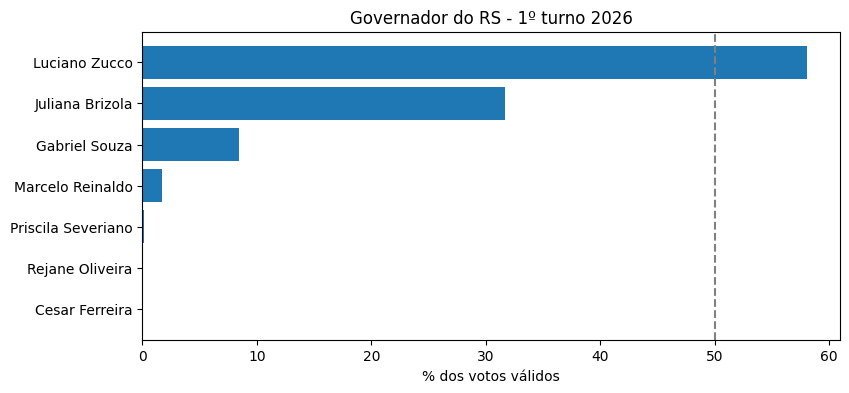

In [20]:
plt.figure(figsize=(9, 4))
plt.barh(resultado.index, resultado["percentual"])
plt.axvline(50, color="gray", linestyle="--")   # linha dos 50%
plt.gca().invert_yaxis()                          # mais votado em cima
plt.xlabel("% dos votos válidos")
plt.title("Governador do RS - 1º turno 2026")
plt.show()

### 4.2 Brancos e nulos (pergunta 2)

In [21]:
por_tipo = votos.groupby("TIPO_VOTO")["QT_VOTOS"].sum()
print((por_tipo / por_tipo.sum() * 100).round(2))

TIPO_VOTO
Branco     4.84
Nulo       4.72
Válido    90.44
Name: QT_VOTOS, dtype: float64


In [22]:
# cidades com mais brancos + nulos
brancos_nulos = votos[votos["TIPO_VOTO"] != "Válido"].groupby("NM_MUNICIPIO")["QT_VOTOS"].sum()
pct_brancos_nulos = brancos_nulos / total_municipio * 100

print("Cidades com maior % de brancos + nulos:")
print(pct_brancos_nulos.sort_values(ascending=False).head(5).round(1))

Cidades com maior % de brancos + nulos:
NM_MUNICIPIO
CHUÍ                    20.4
CERRITO                 17.1
PINHEIRO MACHADO        16.9
CAPÃO DO LEÃO           16.3
SANTANA DA BOA VISTA    16.1
Name: QT_VOTOS, dtype: float64


### 4.3 Quem venceu em cada município (pergunta 3)

In [23]:
# idxmax(axis=1) devolve o nome da coluna com o maior valor de cada linha
vencedor_municipio = pct_municipio.idxmax(axis=1)
municipios_ganhos = vencedor_municipio.value_counts()
municipios_ganhos

,count
Luciano Zucco,475
Juliana Brizola,22


In [24]:
# cidades onde o vencedor do estado perdeu
outros = pct_municipio[vencedor_municipio != vencedor]
print(vencedor, "perdeu em", len(outros), "dos", len(pct_municipio), "municípios:")

segundo = resultado.index[1]
outros[[vencedor, segundo]].sort_values(segundo, ascending=False).round(1)

Luciano Zucco perdeu em 22 dos 497 municípios:


CANDIDATO,Luciano Zucco,Juliana Brizola
NM_MUNICIPIO,,
HERVAL,36.1,55.5
ITATIBA DO SUL,42.0,53.8
PEDRAS ALTAS,42.1,53.1
PINHEIRO MACHADO,39.0,52.9
RIO GRANDE,38.6,52.0
CHUÍ,40.2,50.2
PEDRO OSÓRIO,39.1,49.7
ARROIO GRANDE,44.7,49.5
HULHA NEGRA,44.8,49.2


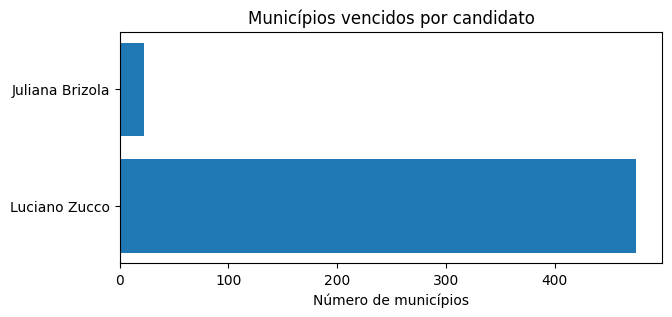

In [25]:
plt.figure(figsize=(7, 3))
plt.barh(municipios_ganhos.index, municipios_ganhos.values)
plt.xlabel("Número de municípios")
plt.title("Municípios vencidos por candidato")
plt.show()

### 4.4 Cidades grandes x cidades pequenas (pergunta 4)
Média do percentual dos 3 mais votados em cada porte de cidade.

In [26]:
top3 = list(resultado.index[:3])

por_porte = pct_municipio[top3].groupby(porte).mean()
por_porte = por_porte.loc[ordem_porte]
por_porte.round(1)

CANDIDATO,Luciano Zucco,Juliana Brizola,Gabriel Souza
QT_VOTOS,,,
Até 5 mil,60.7,25.1,13.4
5 a 20 mil,60.1,28.6,10.0
20 a 100 mil,62.6,27.4,7.8
Mais de 100 mil,54.2,37.0,6.8


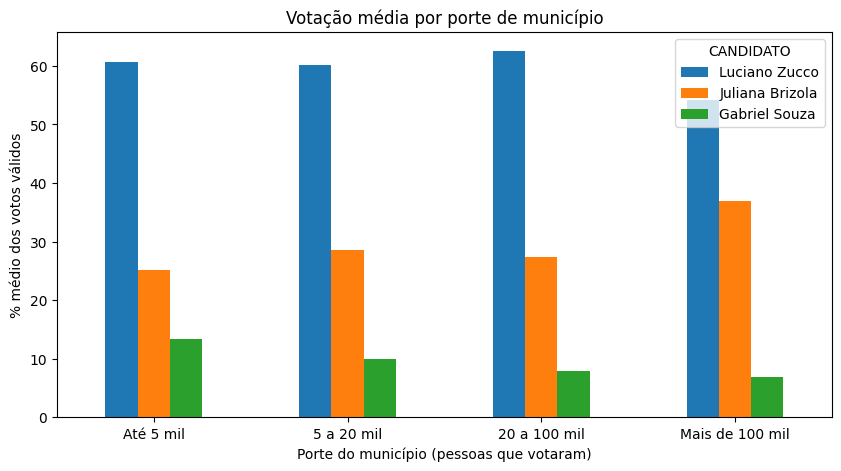

In [27]:
por_porte.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Porte do município (pessoas que votaram)")
plt.ylabel("% médio dos votos válidos")
plt.title("Votação média por porte de município")
plt.xticks(rotation=0)
plt.show()

### 4.5 Consultar uma cidade
Troque o nome abaixo (em maiúsculas e com acento) para ver o resultado de qualquer cidade.

In [29]:
cidade = "SANTA ROSA"

if cidade in pct_municipio.index:
    print(cidade, "-", total_municipio[cidade], "pessoas votaram")
    print(pct_municipio.loc[cidade].sort_values(ascending=False).round(2))
else:
    print("Cidade não encontrada, confira como está escrito.")

SANTA ROSA - 47423 pessoas votaram
CANDIDATO
Luciano Zucco         68.66
Juliana Brizola       22.75
Gabriel Souza          7.80
Marcelo Reinaldo       0.67
Priscila Severiano     0.05
Rejane Oliveira        0.05
Cesar Ferreira         0.01
Name: SANTA ROSA, dtype: float64


## 5. Conclusão

1. Luciano Zucco ganhou no 1º turno, com 58,05% dos votos válidos (cerca de 3,5 milhões de votos). Juliana Brizola ficou em segundo com 31,65% e Gabriel Souza em terceiro com 8,43%. Os outros quatro candidatos juntos tiveram menos de 2%.
2. Brancos e nulos foram 9,6% de todos os votos (4,8% brancos e 4,7% nulos). O Chuí teve o maior percentual, 20,4%.
3. Zucco ganhou em 475 dos 497 municípios. Brizola ganhou em 22, a maioria na metade sul (Rio Grande, Herval, Pinheiro Machado, Chuí, Santa Vitória do Palmar) e também em Porto Alegre (45,8% x 43,9%).
4. Nas cidades com mais de 100 mil votantes, Brizola teve em média 37% e Zucco 54%. Nas cidades menores, Zucco passou de 60%. Gabriel Souza foi melhor nas cidades pequenas (13,4% nas de até 5 mil, contra 6,8% nas grandes). Ou seja, a disputa foi mais equilibrada nas cidades grandes e a vantagem do Zucco veio do interior.

Alguns limites na analise:
- O arquivo tem os votos, mas não tem o número de eleitores aptos, então não dá para calcular a abstenção. Para isso precisaria de outro arquivo do TSE (detalhe da votação por seção).
- As médias por porte tratam todas as cidades com o mesmo peso, não importa o tamanho. Elas mostram onde cada candidato foi melhor, mas não explicam o porquê.